# 01 – Q-learning'e ısınma: Buz gölü (FrozenLake)

Asıl projeye geçmeden önce Q-learning'i en küçük örnekte görüyoruz.

**Oyun:** 4×4 buz gölü. `S` başlangıç, `G` hedef, `H` delik, `F` sağlam buz.
Ajan her adımda sol / aşağı / sağ / yukarı seçer. Hedefe varırsa **+1** ödül, deliğe düşerse oyun biter (0).

**Bizim projeyle eşleşme:**

| Buz gölü | Bizim proje |
|---|---|
| Durum = ajanın bulunduğu kare (16 durum) | Durum = görüntünün parlaklık/kontrast/gürültü aralığı (60 durum) |
| Eylem = 4 yön | Eylem = 6 filtre (aydınlat, CLAHE, …, dur) |
| Ödül = hedefe varınca 1 | Ödül = SSIM ne kadar arttı |


In [1]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

env = gym.make("FrozenLake-v1", is_slippery=False)   # kaygan değil: seçtiğin yöne gider
print(env.unwrapped.desc.astype(str))
print("Durum sayısı:", env.observation_space.n, " Eylem sayısı:", env.action_space.n)

[['S' 'F' 'F' 'F']
 ['F' 'H' 'F' 'H']
 ['F' 'F' 'F' 'H']
 ['H' 'F' 'F' 'G']]
Durum sayısı: 16  Eylem sayısı: 4


## Q-tablosu
Q[durum, eylem] = "bu karede bu yöne gidersem, bundan sonra toplam ne kadar ödül beklerim?"
Başta hiçbir şey bilmiyoruz → hepsi 0.

In [2]:
Q = np.zeros((env.observation_space.n, env.action_space.n))
alfa, gama = 0.1, 0.95          # öğrenme hızı, geleceğe verilen önem
epsilon = 1.0                    # keşif olasılığı (başta hep rastgele)
rng = np.random.default_rng(0)

## Güncelleme kuralı

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,\underbrace{r + \gamma \max_{a'} Q(s',a')}_{\text{hedef}} - Q(s,a)\,]$$

- **s, a:** şimdiki durum ve seçtiğim eylem · **r:** aldığım ödül · **s':** vardığım yeni durum
- **hedef:** "şimdi aldığım + vardığım yerden alabileceğim en iyisi (biraz indirimli)"
- **α (0,1):** tahminimi hedefe doğru %10 kaydır, birden atlama
- Örnek: Q(s,a)=0, r=0, yeni karenin en iyi değeri 0,5 → hedef = 0 + 0,95·0,5 = 0,475 → yeni Q = 0 + 0,1·(0,475 − 0) = **0,0475**

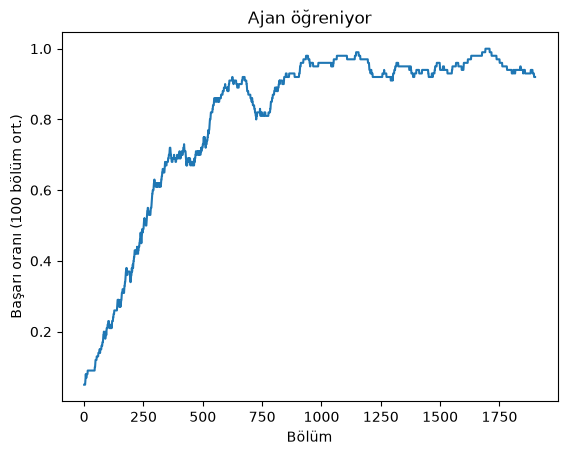

In [3]:
odul_gecmisi = []
for bolum in range(2000):
    s, _ = env.reset(seed=bolum)
    bitti, toplam = False, 0
    while not bitti:
        # keşfet ya da kullan
        a = env.action_space.sample() if rng.random() < epsilon else int(np.argmax(Q[s]))
        s2, r, terminated, truncated, _ = env.step(a)
        bitti = terminated or truncated
        hedef = r if terminated else r + gama * Q[s2].max()
        Q[s, a] += alfa * (hedef - Q[s, a])
        s, toplam = s2, toplam + r
    epsilon = max(0.05, epsilon * 0.997)
    odul_gecmisi.append(toplam)

plt.plot(np.convolve(odul_gecmisi, np.ones(100)/100, mode="valid"))
plt.xlabel("Bölüm"); plt.ylabel("Başarı oranı (100 bölüm ort.)"); plt.title("Ajan öğreniyor"); plt.show()

## Öğrenilen tablo: her karede en iyi yön

Not: Ajanın hiç uğramadığı karelerde Q değerleri hep 0 kalır; orada görünen ← ok anlamsızdır (eşitlikte ilk eylem seçiliyor).

In [4]:
oklar = np.array(["←", "↓", "→", "↑"])
harita = env.unwrapped.desc.astype(str)
politika = np.where(np.isin(harita, ["H", "G"]), harita, oklar[Q.argmax(1)].reshape(4, 4))
print(politika)
print("\nQ-tablosu (satır = kare, sütun = ← ↓ → ↑):")
print(np.round(Q, 2))

[['↓' '←' '←' '←']
 ['↓' 'H' '↓' 'H']
 ['→' '↓' '←' 'H']
 ['H' '→' '→' 'G']]

Q-tablosu (satır = kare, sütun = ← ↓ → ↑):
[[0.73 0.77 0.69 0.73]
 [0.73 0.   0.06 0.39]
 [0.23 0.02 0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.77 0.81 0.   0.73]
 [0.   0.   0.   0.  ]
 [0.   0.23 0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.81 0.   0.86 0.77]
 [0.81 0.9  0.81 0.  ]
 [0.86 0.32 0.   0.02]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.9  0.95 0.85]
 [0.9  0.95 1.   0.8 ]
 [0.   0.   0.   0.  ]]


## ✅ Kendini test et
1. Hedefin hemen solundaki karede (durum 14) en büyük Q değeri hangi eylemde? Neden?
2. `epsilon` hiç azalmasaydı (hep 1,0) ne olurdu? Kodu değiştirip dene.
3. `gama = 0.5` yap. Başlangıç karesinin Q değerleri küçüldü mü? Neden?

> Bizim projede tek fark: Durumu kare numarası değil `src/env.py`'deki `durum_no(img)` veriyor, ödülü de SSIM artışı.